# EDA - Dataset de Estaciones de Ferrocarril 2022
## Análisis de Datos - Actividad 2
### Estudiante: Brayan Torrealba (a2915)
### Fecha: Noviembre 2026

## 1. Introducción

Este análisis exploratorio de datos (EDA) examina el dataset `dataset_estaciones_ffcc_2022.csv`, que contiene información sobre las estaciones de ferrocarril en servicio durante el año 2022 en Argentina. Los datos provienen del portal de datos abiertos del gobierno argentino: [datos.gob.ar — Estaciones de trenes y servicios activos a 2022](https://datos.gob.ar/dataset/estaciones-de-trenes-y-servicios-activos-a-2022).

### Objetivos
1. Realizar estadística descriptiva del dataset
2. Identificar y describir los tipos de variables
3. Analizar relaciones entre variables
4. Crear al menos 3 gráficos diferentes

## 2. Descripción del dataset

El dataset cuenta con las siguientes variables:

| Columna | Tipo (fuente) | Descripción |
|---------|--------------|-------------|
| `_id`   | Entero       | Índice interno del dataset |
| `FID`   | Texto        | Código único identificativo de la fila |
| `id`    | Entero       | Identificador numérico de la estación |
| `gna`   | Texto        | Término genérico: tipo de instalación ferroviaria (ej: Estación, Taller, Empalme) |
| `nam`   | Texto        | Nombre corto de la instalación ferroviaria |
| `fna`   | Texto        | Nombre largo / geográfico de la instalación ferroviaria |
| `línea` | Texto        | Nombre de la línea ferroviaria (ej: Mitre, Sarmiento, Roca) |
| `caa`   | Texto        | Nombre de la operadora ferroviaria (ej: SOFSE) |
| `progresiva` | Decimal | Kilómetro desde el origen de la línea |
| `fuente` | Texto       | Fuente del dato (ej: Operador) |
| `geom`  | GeoPoint     | Coordenadas geográficas en formato WKT (POINT lon lat) |
| `long`  | Decimal      | Longitud geográfica |
| `lat`   | Decimal      | Latitud geográfica |

## 3. Configuración e importación de librerías

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

## 4. Carga y preparación de datos

In [ ]:
# Carga del dataset
# Nota: las columnas 'long' y 'lat' vienen con puntos como separadores de miles
# (ej: -5.999.612.956), por eso se leen como string y se convierten manualmente.

df = pd.read_csv('dataset_estaciones_ffcc_2022.csv', sep=';', encoding='utf-8')

print(f'Filas: {df.shape[0]}')
print(f'Columnas: {df.shape[1]}')
display(df.head(10))

Filas: 464
Columnas: 13


,_id,FID,id,gna,nam,fna,línea,caa,progresiva,fuente,geom,long,lat
0,1,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,520,Estación,Chivilcoy Sud,Estación Chivilcoy Sud,FFCC Sarmiento,SOFSE,NaN,NaN,POINT (-59.99612955939485 -34.91741632895207),-5.999.612.956,-3.491.741.633
1,2,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,521,Estación,Andrés Vaccareza (Alberti),Estación Andrés Vaccareza (Alberti),FFCC Sarmiento,SOFSE,NaN,NaN,POINT (-60.27756731340126 -35.03459707121156),-6.027.756.731,-3.503.459.707
2,3,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,523,Estación,Suipacha,Estación Suipacha,FFCC Sarmiento,SOFSE,NaN,NaN,POINT (-59.69040669399509 -34.77327428069938),-5.969.040.669,-3.477.327.428
3,4,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,524,Estación,Bragado,Estación Bragado,FFCC Sarmiento,SOFSE,NaN,NaN,POINT (-60.47851942286195 -35.11974437531145),-6.047.851.942,-3.511.974.438
4,5,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,528,Estación,Mercedes,Estación Mercedes,FFCC Sarmiento,SOFSE,NaN,NaN,POINT (-59.43242108405843 -34.65767692959696),-5.943.242.108,-3.465.767.693
5,6,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,48,Estación,Haedo,Estación Haedo,FFCC Sarmiento,SOFSE,17.66,Operador,POINT (-58.59194588896136 -34.644477144900506),-5.859.194.589,-3.464.447.714
6,7,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,84,Estación,Once,Estación Once,FFCC Sarmiento,SOFSE,0.00,Operador,POINT (-58.4075158087721 -34.60827979749716),-5.840.751.581,-346.082.798
7,8,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,10,Estación,Kilómetro 16 Maniobras,Estación Kilómetro 16 Maniobras,Mitre,SOFSE,NaN,Operador,POINT (-58.515622809061675 -34.581242423818246),-5.851.562.281,-3.458.124.242
8,9,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,12,Estación,Saavedra,Estación Saavedra,Mitre,SOFSE,12.30,Operador,POINT (-58.487042938761256 -34.55407485033733),-5.848.704.294,-3.455.407.485
9,10,Estacion_ffcc_serv_22.view.fid--eb08bae_1a13e5...,18,Estación,3 de Febrero,Estación 3 de Febrero,Mitre,SOFSE,5.66,Operador,POINT (-58.425288888889376 -34.571905555555325),-5.842.528.889,-3.457.190.556


In [ ]:
# Conversión de coordenadas: quitar puntos de miles y convertir a float
def limpiar_coordenada(valor):
    """Convierte '-5.999.612.956' -> -59.99612956 (eliminando separadores de miles)"""
    if pd.isna(valor):
        return np.nan
    s = str(valor).strip()
    if s.count('.') > 1:
        neg = s.startswith('-')
        s = s.lstrip('-').replace('.', '')
        s = ('-' if neg else '') + s[:2] + '.' + s[2:]
    try:
        return float(s)
    except ValueError:
        return np.nan

df['long'] = df['long'].apply(limpiar_coordenada)
df['lat']  = df['lat'].apply(limpiar_coordenada)
df['progresiva'] = pd.to_numeric(df['progresiva'], errors='coerce')

print('Conversiones aplicadas:')
print(f"  long → {df['long'].notna().sum()} valores válidos, rango [{df['long'].min():.2f}, {df['long'].max():.2f}]")
print(f"  lat  → {df['lat'].notna().sum()} valores válidos, rango [{df['lat'].min():.2f}, {df['lat'].max():.2f}]")
print(f"  progresiva → {df['progresiva'].notna().sum()} valores válidos")

Conversiones aplicadas:
  long → 447 valores válidos, rango [-586.86, -55.85]
  lat  → 447 valores válidos, rango [-38.96, -24.66]
  progresiva → 273 valores válidos


## 5. Calidad de datos

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 464 entries, 0 to 463
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _id         464 non-null    int64  
 1   FID         464 non-null    object 
 2   id          464 non-null    int64  
 3   gna         435 non-null    object 
 4   nam         463 non-null    object 
 5   fna         435 non-null    object 
 6   línea       463 non-null    object 
 7   caa         430 non-null    object 
 8   progresiva  273 non-null    float64
 9   fuente      263 non-null    object 
 10  geom        464 non-null    object 
 11  long        447 non-null    object 
 12  lat         447 non-null    object 
dtypes: float64(1), int64(2), object(10)
memory usage: 47.3+ KB


In [ ]:
# Valores nulos
nulos = pd.DataFrame({
    'Nulos': df.isnull().sum(),
    'Porcentaje (%)': (df.isnull().sum() / len(df) * 100).round(1)
})
nulos = nulos[nulos['Nulos'] > 0].sort_values('Porcentaje (%)', ascending=False)

if len(nulos) > 0:
    print('Columnas con valores nulos:')
    display(nulos)
else:
    print('No hay valores nulos.')

print(f'\nFilas duplicadas: {df.duplicated().sum()}')

Columnas con valores nulos:


,Nulos,Porcentaje (%)
fuente,201,43.30
progresiva,191,41.20
caa,34,7.30
gna,29,6.20
fna,29,6.20
long,17,3.70
lat,17,3.70
línea,1,0.20
nam,1,0.20



Filas duplicadas: 0


In [ ]:
# Inconsistencias en la variable 'línea'
# Una misma línea puede aparecer con nombres distintos
# (ej: 'Sarmiento' y 'FFCC Sarmiento'). No son duplicados técnicos
# sino un problema de normalización de la variable categórica.

print('Valores únicos en la columna línea:')
for val in sorted(df['línea'].dropna().unique()):
    print(f'  {val}')

print('\nPosibles inconsistencias detectadas:')
lineas = df['línea'].dropna().unique()
keywords = ['Sarmiento', 'Mitre', 'Roca', 'San Martín', 'San Martin', 'Belgrano', 'Urquiza']
for kw in keywords:
    matches = [l for l in lineas if kw.lower() in l.lower()]
    if len(matches) > 1:
        print(f'  "{kw}" aparece en: {matches}')

Valores únicos en la columna línea:
  Belgrano Norte
  Belgrano Sur
  FFCC Belgrano
  FFCC Mitre
  FFCC Roca
  FFCC Roca no operativo
  FFCC San Martín
  FFCC Sarmiento
  FFCC Urquiza
  Mitre
  Roca
  San Martín
  Sarmiento
  Urquiza

Posibles inconsistencias detectadas:
  "Sarmiento" aparece en: ['FFCC Sarmiento', 'Sarmiento']
  "Mitre" aparece en: ['Mitre', 'FFCC Mitre']
  "Roca" aparece en: ['FFCC Roca no operativo', 'Roca', 'FFCC Roca']
  "San Martín" aparece en: ['FFCC San Martín', 'San Martín']
  "Belgrano" aparece en: ['Belgrano Sur', 'FFCC Belgrano', 'Belgrano Norte']
  "Urquiza" aparece en: ['Urquiza', 'FFCC Urquiza']


## 6. Estadística descriptiva

In [ ]:
# Variables numéricas
print('=== Variables numéricas ===')
display(df[['progresiva', 'long', 'lat']].describe())

=== Variables numéricas ===


,progresiva
count,273.00
mean,28.78
std,23.89
min,0.00
25%,13.00
50%,22.87
75%,38.00
max,203.30


In [ ]:
# Variables categóricas
print('=== Variables categóricas ===')
for col in ['gna', 'línea', 'caa', 'fuente']:
    print(f'\n--- {col} ---')
    print(f'  Valores únicos: {df[col].nunique()}')
    display(df[col].value_counts().rename_axis(col).reset_index(name='Cantidad'))

## 7. Tipos de variables

Clasificación de las variables del dataset según su naturaleza estadística:

In [ ]:
clasificacion = pd.DataFrame([
    ('_id',        'Cuantitativa discreta',  'Índice interno del registro'),
    ('FID',        'Cualitativa nominal',    'Código único de fila (texto)'),
    ('id',         'Cuantitativa discreta',  'ID numérico de la estación'),
    ('gna',        'Cualitativa nominal',    'Tipo de instalación: Estación, Taller, Empalme'),
    ('nam',        'Cualitativa nominal',    'Nombre corto de la instalación'),
    ('fna',        'Cualitativa nominal',    'Nombre largo de la instalación'),
    ('línea',      'Cualitativa nominal',    'Línea ferroviaria a la que pertenece'),
    ('caa',        'Cualitativa nominal',    'Operadora ferroviaria (ej: SOFSE)'),
    ('progresiva', 'Cuantitativa continua',  'Kilómetro desde el origen de la línea'),
    ('fuente',     'Cualitativa nominal',    'Fuente del dato (ej: Operador)'),
    ('geom',       'Cualitativa nominal',    'Coordenadas en texto WKT (POINT lon lat)'),
    ('long',       'Cuantitativa continua',  'Longitud geográfica (grados decimales)'),
    ('lat',        'Cuantitativa continua',  'Latitud geográfica (grados decimales)'),
], columns=['Variable', 'Tipo estadístico', 'Descripción'])

display(clasificacion)

,Variable,Tipo estadístico,Descripción
0,_id,Cuantitativa discreta,Índice interno del registro
1,FID,Cualitativa nominal,Código único de fila (texto)
2,id,Cuantitativa discreta,ID numérico de la estación
3,gna,Cualitativa nominal,"Tipo de instalación: Estación, Taller, Empalme"
4,nam,Cualitativa nominal,Nombre corto de la instalación
5,fna,Cualitativa nominal,Nombre largo de la instalación
6,línea,Cualitativa nominal,Línea ferroviaria a la que pertenece
7,caa,Cualitativa nominal,Operadora ferroviaria (ej: SOFSE)
8,progresiva,Cuantitativa continua,Kilómetro desde el origen de la línea
9,fuente,Cualitativa nominal,Fuente del dato (ej: Operador)


## 8. Visualizaciones

### Gráfico 1 — Barras: estaciones por línea (valores originales)

Muestra la cantidad de instalaciones registradas para cada valor de `línea` tal como aparece en el dataset, sin ninguna normalización. Sirve como punto de partida para visualizar el problema de inconsistencia de nombres.

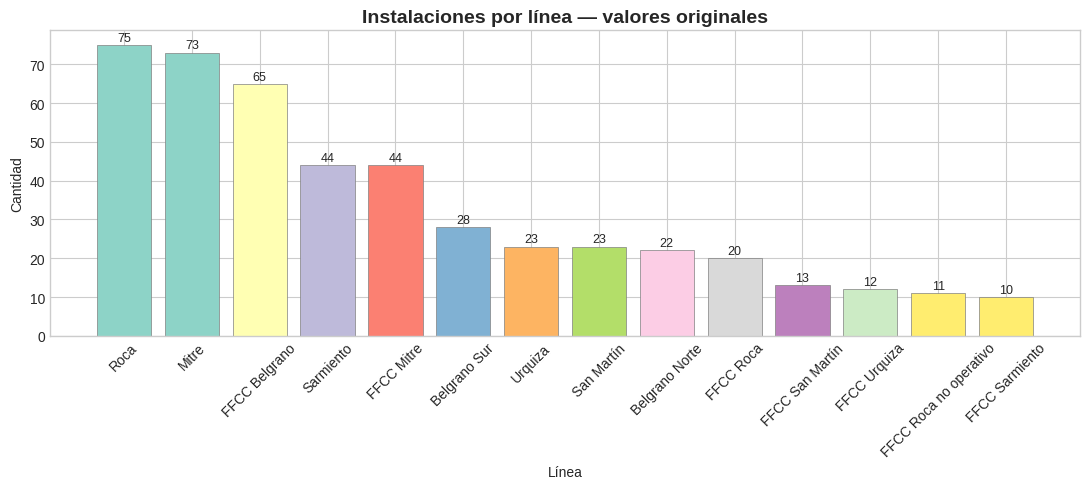

In [ ]:
conteo = df['línea'].value_counts()

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(conteo.index, conteo.values,
              color=plt.cm.Set3(np.linspace(0, 1, len(conteo))),
              edgecolor='gray', linewidth=0.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=9)

ax.set_title('Instalaciones por línea — valores originales', fontsize=14, fontweight='bold')
ax.set_xlabel('Línea')
ax.set_ylabel('Cantidad')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Gráfico 2 — Barras: estaciones por línea (variantes agrupadas)

El mismo conteo pero con las variantes de nombre unificadas bajo una etiqueta común. Permite ver la distribución real sin la distorsión causada por las inconsistencias de nomenclatura.

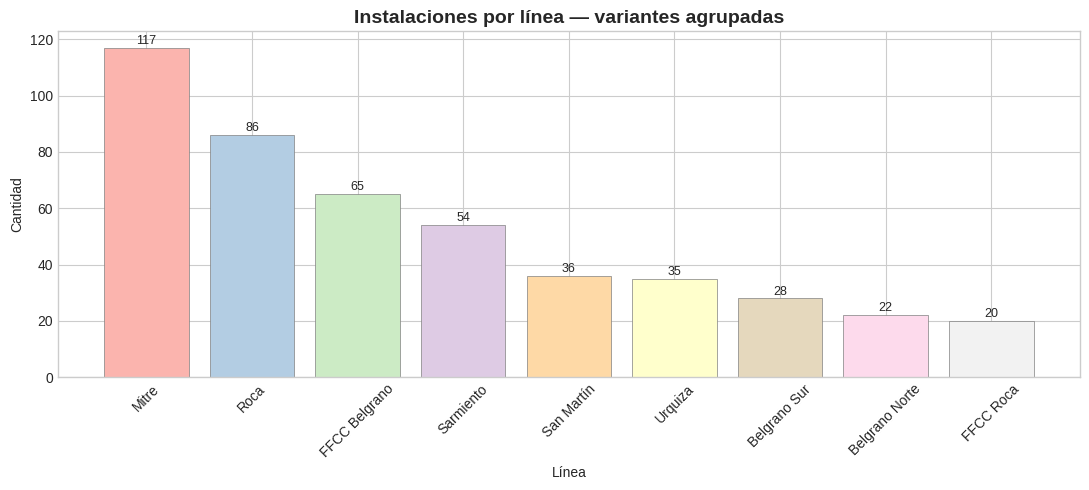


Tabla de frecuencias (normalizada):


,Cantidad,Porcentaje (%)
línea_norm,,
Mitre,117,25.20
Roca,86,18.50
FFCC Belgrano,65,14.00
Sarmiento,54,11.60
San Martín,36,7.80
Urquiza,35,7.50
Belgrano Sur,28,6.00
Belgrano Norte,22,4.70
FFCC Roca,20,4.30


In [ ]:
# Mapa de normalización: variantes -> nombre canónico
normalizacion = {
    'FFCC Sarmiento':         'Sarmiento',
    'FFCC San Martín':        'San Martín',
    'FFCC Roca no operativo': 'Roca',
    'FFCC Belgrano Norte':    'Belgrano Norte',
    'FFCC Belgrano Sur':      'Belgrano Sur',
    'FFCC Urquiza':           'Urquiza',
    'FFCC Mitre':             'Mitre',
}

df['línea_norm'] = df['línea'].replace(normalizacion)

conteo_norm = df['línea_norm'].value_counts()

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(conteo_norm.index, conteo_norm.values,
              color=plt.cm.Pastel1(np.linspace(0, 1, len(conteo_norm))),
              edgecolor='gray', linewidth=0.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=9)

ax.set_title('Instalaciones por línea — variantes agrupadas', fontsize=14, fontweight='bold')
ax.set_xlabel('Línea')
ax.set_ylabel('Cantidad')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('\nTabla de frecuencias (normalizada):')
freq = pd.DataFrame({
    'Cantidad': conteo_norm,
    'Porcentaje (%)': (conteo_norm / len(df) * 100).round(1)
})
display(freq)

### Gráfico 3 — Barras horizontales: estaciones más septentrionales y más meridionales

En Argentina las latitudes son negativas: cuanto más negativa, más al sur. Se muestran las 5 estaciones con la latitud más alta (más al norte) y las 5 con la latitud más baja (más al sur), con la línea a la que pertenecen.

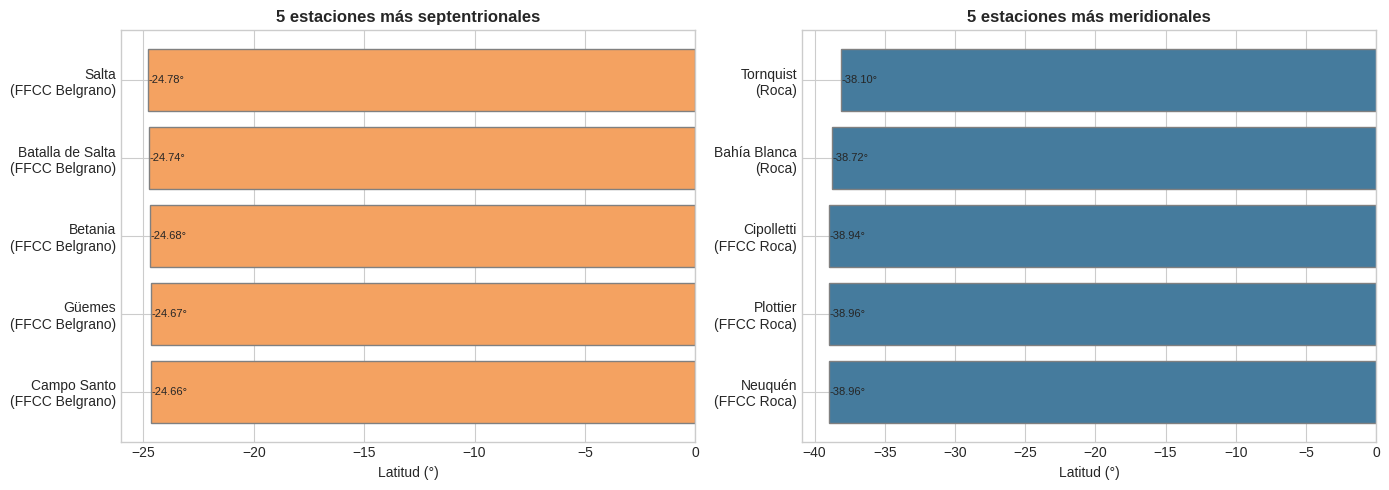

Estaciones más al norte:


,Estación (línea),Latitud
0,Campo Santo\n(FFCC Belgrano),-24.66
1,Güemes\n(FFCC Belgrano),-24.67
2,Betania\n(FFCC Belgrano),-24.68
3,Batalla de Salta\n(FFCC Belgrano),-24.74
4,Salta\n(FFCC Belgrano),-24.78



Estaciones más al sur:


,Estación (línea),Latitud
0,Neuquén\n(FFCC Roca),-38.96
1,Plottier\n(FFCC Roca),-38.96
2,Cipolletti\n(FFCC Roca),-38.94
3,Bahía Blanca\n(Roca),-38.72
4,Tornquist\n(Roca),-38.10


In [ ]:
# Estaciones con coordenadas válidas
df_coords = df.dropna(subset=['lat', 'nam', 'línea_norm']).copy()

# Etiqueta: nombre de estación + línea
df_coords['etiqueta'] = df_coords['nam'] + '\n(' + df_coords['línea_norm'] + ')'

top5_norte = df_coords.nlargest(5, 'lat')[['etiqueta', 'lat']].reset_index(drop=True)
top5_sur   = df_coords.nsmallest(5, 'lat')[['etiqueta', 'lat']].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 5 más al norte
axes[0].barh(top5_norte['etiqueta'], top5_norte['lat'],
             color='#f4a261', edgecolor='gray')
axes[0].set_title('5 estaciones más septentrionales', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Latitud (°)')
for i, val in enumerate(top5_norte['lat']):
    axes[0].text(val + 0.02, i, f'{val:.2f}°', va='center', fontsize=8)

# Top 5 más al sur
axes[1].barh(top5_sur['etiqueta'], top5_sur['lat'],
             color='#457b9d', edgecolor='gray')
axes[1].set_title('5 estaciones más meridionales', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Latitud (°)')
for i, val in enumerate(top5_sur['lat']):
    axes[1].text(val + 0.02, i, f'{val:.2f}°', va='center', fontsize=8)

plt.tight_layout()
plt.show()

print('Estaciones más al norte:')
display(top5_norte.rename(columns={'etiqueta': 'Estación (línea)', 'lat': 'Latitud'}))
print('\nEstaciones más al sur:')
display(top5_sur.rename(columns={'etiqueta': 'Estación (línea)', 'lat': 'Latitud'}))

### Gráfico 4 — Barras: operadoras con más instalaciones a cargo

Muestra cuántas instalaciones tiene a cargo cada operadora (`caa`). Permite ver la concentración de la operación ferroviaria en Argentina.

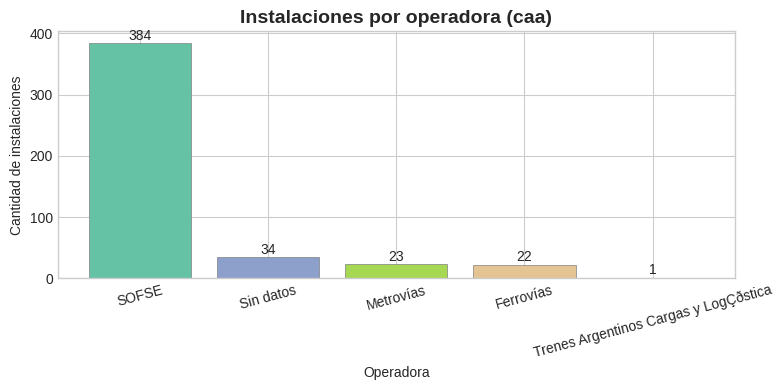


Detalle:


,Operadora,Instalaciones,Porcentaje (%)
0,SOFSE,384,82.80
1,Sin datos,34,7.30
2,Metrovías,23,5.00
3,Ferrovías,22,4.70
4,Trenes Argentinos Cargas y LogÇðstica,1,0.20


In [ ]:
conteo_op = df['caa'].value_counts(dropna=False)
# Reemplazar NaN por etiqueta legible
conteo_op.index = conteo_op.index.fillna('Sin datos')

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(conteo_op.index, conteo_op.values,
              color=plt.cm.Set2(np.linspace(0, 1, len(conteo_op))),
              edgecolor='gray', linewidth=0.5)

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.5,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=10)

ax.set_title('Instalaciones por operadora (caa)', fontsize=14, fontweight='bold')
ax.set_xlabel('Operadora')
ax.set_ylabel('Cantidad de instalaciones')
ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.show()

print('\nDetalle:')
display(pd.DataFrame({
    'Operadora': conteo_op.index,
    'Instalaciones': conteo_op.values,
    'Porcentaje (%)': (conteo_op.values / len(df) * 100).round(1)
}))

## 9. Relación entre variables

In [ ]:
# Correlación entre las variables numéricas continuas
corr = df[['progresiva', 'long', 'lat']].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=1, ax=ax)
ax.set_title('Matriz de correlación — variables numéricas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Tabla de contingencia: tipo de instalación vs línea (normalizada)
tabla = pd.crosstab(df['gna'], df['línea_norm'])
print('Tabla de contingencia: tipo de instalación vs línea')
display(tabla)

## 10. Conclusiones

**Sobre el dataset:**
- Contiene 13 variables sobre instalaciones ferroviarias argentinas en 2022.
- La variable `progresiva` tiene valores nulos en estaciones de líneas no operativas.
- Las coordenadas `long` y `lat` requirieron limpieza por un formato no estándar (puntos como separadores de miles).
- Se detectaron inconsistencias en `línea`: una misma línea aparece con nombres distintos (ej: `Sarmiento` y `FFCC Sarmiento`). No son duplicados sino un problema de normalización que distorsiona los conteos agrupados. Se aplicó una normalización manual para los gráficos comparativos.

**Sobre la distribución de estaciones:**
- Mitre y Sarmiento concentran la mayor cantidad de instalaciones, lo que refleja la densidad del servicio en el conurbano bonaerense.
- La mayoría de las instalaciones son de tipo **Estación** según `gna`.
- Las líneas con mayor extensión geográfica (que llegan más al sur o al norte) son aquellas vinculadas al servicio de larga distancia.

**Sobre operadoras:**
- La operación ferroviaria está fuertemente concentrada en SOFSE, que tiene a cargo la gran mayoría de las instalaciones del dataset.

**Alcance y limitaciones del dataset:**
- El dataset cubre exclusivamente la red ferroviaria de pasajeros operada por SOFSE y concesionarias, centrada en el área metropolitana de Buenos Aires y algunos ramales al interior. No incluye servicios ferroviarios turísticos —como el **Tren del Fin del Mundo** (Ushuaia, ~54°S), considerado el tren más austral del mundo— ni servicios de carga. Por lo tanto, no representa la totalidad de la infraestructura ferroviaria argentina.

- Existe correlación entre `long` y `lat`, esperable dado que las líneas ferroviarias argentinas siguen trayectorias diagonales desde Buenos Aires hacia el interior del país.

## Referencias
- Dataset: `dataset_estaciones_ffcc_2022.csv` — fuente: [datos.gob.ar — Estaciones de trenes y servicios activos a 2022](https://datos.gob.ar/dataset/estaciones-de-trenes-y-servicios-activos-a-2022)
- Herramientas: Python, Pandas, NumPy, Matplotlib, Seaborn
- Basado en ejemplos de: Clase 2 — Introducción al EDA
- Curso: Análisis de Datos — CEIA